# Block 3: Distribution of Returns

**Objective.** Test whether S&P 500 daily returns are normally distributed, and whether they show the
stylized facts documented in the literature (Cont, 2001): fat tails, absence of autocorrelation in returns,
and strong autocorrelation in absolute returns (volatility clustering, Engle, 1982).

**Method.** Each test is run on raw daily log returns and on volatility-standardized returns
`z_t = r_t / sigma_(t-1)`, where `sigma_(t-1)` is the 21-day volatility up to the previous day
(no look-ahead). Comparing the two shows how much of the non-normality comes from time-varying volatility.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from volrisk.config import FIGURES
from volrisk.data import load_raw
from volrisk.returns import log_returns
from volrisk.distribution import normality_test, autocorrelation, ljung_box, standardized_returns

In [17]:
r = log_returns(load_raw("sp500")["Close"])
z = standardized_returns(r, window=21)
print(f"Raw returns: {len(r)} | Standardized returns: {len(z)}")

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.
Raw returns: 2974 | Standardized returns: 2953


## Normality

The Jarque-Bera test (Jarque & Bera, 1980) combines skewness and excess kurtosis, which are both
zero for a normal distribution. A p-value below 0.05 rejects normality at the 5% level.

,log_return,std_return_21d
n_obs,2974,2953
skewness,-0.6437,-1.048
excess_kurtosis,15.92,5.331
jarque_bera,3.151e+04,4023
p_value,0,0


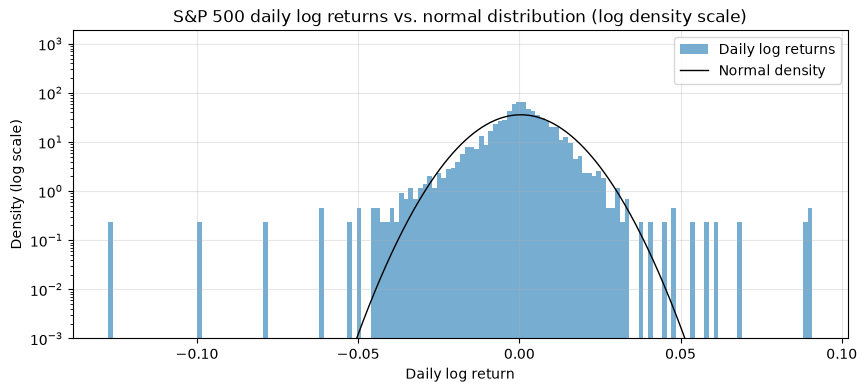

In [18]:
normality = pd.concat([normality_test(r), normality_test(z)], axis=1)
display(normality.style.format("{:.4g}"))

# Histogram of raw returns vs. a normal density with the same mean and standard deviation
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(r, bins=150, density=True, alpha=0.6, label="Daily log returns")
x = np.linspace(r.min(), r.max(), 500)
ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="black", linewidth=1, label="Normal density")
ax.set_yscale("log")  # log scale makes the tails visible
ax.set_ylim(bottom=1e-3)
ax.set_title("S&P 500 daily log returns vs. normal distribution (log density scale)")
ax.set_xlabel("Daily log return")
ax.set_ylabel("Density (log scale)")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "03_histogram_vs_normal.png", dpi=150, bbox_inches="tight")
plt.show()

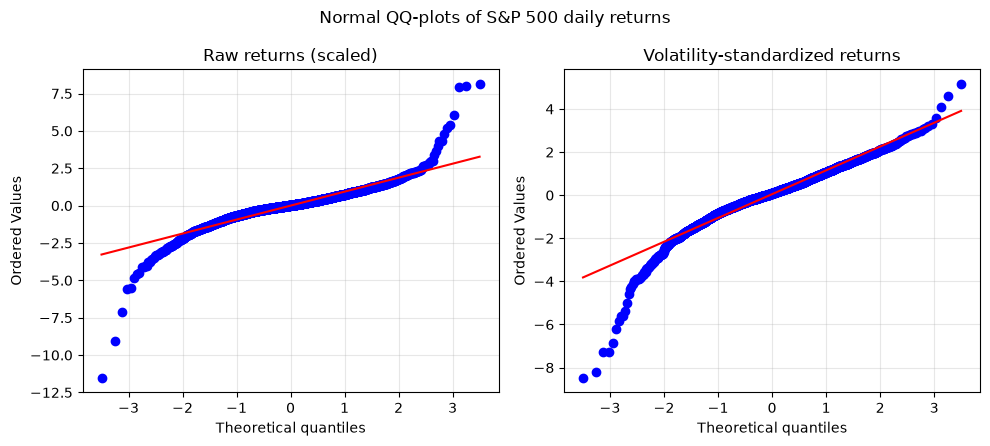

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, series, title in [(axes[0], (r - r.mean()) / r.std(), "Raw returns (scaled)"),
                          (axes[1], z, "Volatility-standardized returns")]:
    stats.probplot(series, dist="norm", plot=ax)
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig.suptitle("Normal QQ-plots of S&P 500 daily returns")
fig.tight_layout()
fig.savefig(FIGURES / "03_qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

### Reading the normality tests

The histogram shows a leptokurtic distribution: a higher peak than the normal density, thinner shoulders
and much fatter tails. Daily moves beyond ±5%, which the normal distribution treats as virtually
impossible, occur several times in the sample.

Normality is strongly rejected for raw returns (excess kurtosis 15.9, Jarque-Bera ≈ 31,500).
Standardizing by the previous day's 21-day volatility removes about two thirds of the excess kurtosis
(down to 5.3): a large part of the fat tails comes from time-varying volatility. Normality is still
rejected, however.

Skewness becomes *more* negative after standardization (from -0.64 to -1.05). The QQ-plots show why:
the upper tail of standardized returns is close to normal, while the lower tail reaches about -8.
Large losses tend to occur after calm periods, when the previous day's volatility is low, so they are
large surprises; large rebounds occur during crises, when volatility is already high. Crashes are
unexpected; rebounds are not. This is consistent with the leverage effect (Black, 1976; Christie, 1982).

## Autocorrelation and volatility clustering

The sample autocorrelation is computed for lags 1 to 20 trading days. Under the null hypothesis of no
autocorrelation, values fall within roughly ±1.96 / sqrt(n) (95% band). The Ljung-Box test
(Ljung & Box, 1978) tests jointly whether all autocorrelations up to lag 20 are zero.
Absolute returns |r| are used as a proxy for volatility: significant autocorrelation in |r|
means that large moves tend to be followed by large moves.

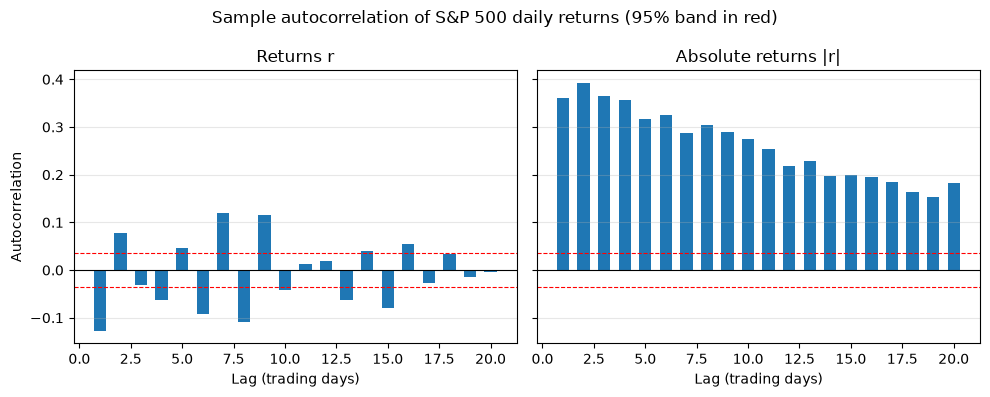

In [20]:
band = 1.96 / np.sqrt(len(r))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, series, title in [(axes[0], r, "Returns r"), (axes[1], r.abs(), "Absolute returns |r|")]:
    acf = autocorrelation(series, max_lag=20)
    ax.bar(acf.index, acf.values, width=0.6)
    ax.axhline(band, color="red", linestyle="--", linewidth=0.8)
    ax.axhline(-band, color="red", linestyle="--", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Lag (trading days)")
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("Autocorrelation")
fig.suptitle("Sample autocorrelation of S&P 500 daily returns (95% band in red)")
fig.tight_layout()
fig.savefig(FIGURES / "03_autocorrelation.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
lb = pd.concat([ljung_box(r), ljung_box(r.abs().rename("abs_log_return")),
                ljung_box(z), ljung_box(z.abs().rename("abs_std_return"))], axis=1)
lb.style.format("{:.4g}")

,log_return,abs_log_return,std_return_21d,abs_std_return
ljung_box_q,289.2,4432,22.28,140.3
p_value,1.297e-49,0,0.3253,4.52e-20


### Reading the autocorrelation tests

- **Returns.** Raw returns show significant autocorrelation (Ljung-Box Q = 289), with a negative first lag
  (about -0.13) and alternating signs, a pattern driven by crash-and-rebound sequences in crisis periods.
  It disappears once returns are standardized (Q = 22.3, p = 0.33): the apparent predictability is an
  artefact of time-varying volatility, which the Ljung-Box test assumes away. Returns are therefore
  essentially unpredictable from their own past.
- **Absolute returns.** Autocorrelation is strong (0.36-0.39 at lags 1-3) and decays very slowly
  (still 0.15-0.18 at lag 20; Q = 4,432): volatility is highly persistent, a long-memory property
  (Ding, Granger & Engle, 1993). Standardization removes most of it (Q = 140) but not all, because a
  21-day rolling window is a crude volatility model. A GARCH(1,1) model (Bollerslev, 1986) would capture
  this persistence more accurately.

In [22]:
from statsmodels.stats.diagnostic import acorr_ljungbox

check = acorr_ljungbox(r, lags=[20])
print(f"Our Ljung-Box Q:  {ljung_box(r)['ljung_box_q']:.2f}")
print(f"statsmodels Q:    {check['lb_stat'].iloc[0]:.2f}")

Our Ljung-Box Q:  289.19
statsmodels Q:    287.91


## Block 3: key takeaways

- S&P 500 daily returns are **not normally distributed**: fat tails (excess kurtosis 15.9) and
  negative skewness, confirming the stylized facts of Cont (2001).
- **Returns are almost unpredictable, but volatility is highly predictable.** Autocorrelation in returns
  vanishes once volatility is accounted for, while absolute returns remain strongly and persistently
  autocorrelated (Engle, 1982).
- **Time-varying volatility explains a large part of the fat tails** (excess kurtosis falls from 15.9 to 5.3
  after standardization), but not all of it, and **crashes remain asymmetric surprises.**
- **Implication for risk measurement:** a normal model with constant volatility underestimates
  extreme losses. Block 5 quantifies this with Value-at-Risk and Expected Shortfall.